# Inside the Search Giant: Sentiment and Topic Analysis of Employee Reviews of Working at Google
### Data Collection, Preprocessing, and Descriptive Analysis
**Author:** Crystal Garcia &nbsp;|&nbsp; **Course:** Social Media Analytics and Text Mining

This notebook covers Project Stage 2: collecting the raw review data, identifying data-quality
issues, cleaning/preprocessing the text, and producing descriptive statistics (word-frequency and
n-gram counts) on the cleaned corpus.

## 1. Data Collection

**Source dataset:** *Glassdoor Job Reviews* (davidgauthier, Kaggle,
`kaggle.com/datasets/davidgauthier/glassdoor-job-reviews`) — ~838,000 employee reviews of
companies scraped from Glassdoor.com, covering 2008–2021. The dataset is also mirrored publicly
on the Hugging Face Hub at `huggingface.co/datasets/lallantop/glassdoor` with an identical schema.

**Collection steps (exact, replicable):**
1. Open `https://huggingface.co/datasets/lallantop/glassdoor` (public mirror, no account/login required).
2. Open the **Data Studio / SQL Console** tab on the dataset page.
3. Run the query: `SELECT * FROM train WHERE firm = 'Google'`
4. Export the query result as CSV (`google-company-data.csv`).

This yields every Glassdoor review tagged with employer = "Google" in the source corpus.
The cell below loads that exported file.

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import CountVectorizer

pd.set_option('display.max_columns', None)
plt.rcParams['figure.dpi'] = 110

df_raw = pd.read_csv('google-company-data.csv')
print(f"Rows collected: {df_raw.shape[0]:,}")
print(f"Columns collected: {df_raw.shape[1]}")
print(f"Date range: {df_raw['date_review'].min()} to {df_raw['date_review'].max()}")
df_raw.head(3)

Rows collected: 15,995
Columns collected: 18
Date range: 2008-02-05 to 2021-06-04


,firm,date_review,job_title,current,location,overall_rating,work_life_balance,culture_values,diversity_inclusion,career_opp,comp_benefits,senior_mgmt,recommend,ceo_approv,outlook,headline,pros,cons
0,Google,2008-02-05,Software Engineer,Current Employee,"Mountain View, CA",4,4.0,NaN,NaN,4.0,4.0,4.0,v,v,o,Freedom within the company and lots of things to do & learn.,I work w/ a diverse set of people. You have have great people within the company w/o a lot of micromanagement. You have the freedom to do a job w/o contantly being checked on.,Google can be a bit overwhelming w/ the volume of things that you have to learn. It can also be chaotic because you do have freedom but so much is always going on at the same time.
1,Google,2008-02-11,Software Engineer,Current Employee,"Mountain View, CA",5,4.0,NaN,NaN,5.0,5.0,5.0,v,v,o,Work with smart people who are willing to share information.,"People are willing to share knowledge which is not the norm in this industry. This is the first place I have worked where the people are great about that. Also, I get to work on cool projects that no one else in the world works on.","A company like this requires a lot of long hours, so the work and life balance is often hard to come by."
2,Google,2008-02-14,Software Engineer,Current Employee,"Mountain View, CA",5,5.0,NaN,NaN,4.0,4.0,5.0,v,v,o,One of the best jobs of my life because I work with such great people.,"To repeat what I wrote before, the people I work for and work with here are very smart and confident people.",Sometimes being that it is such a big company it is sometimes hard to be heard when you need to voice concerns or comments.


## 2. Identifying Issues in the Text Data

Before cleaning, we profile the raw data to identify concrete, fixable problems.

In [2]:
# 2.1 Missing values
missing = df_raw.isna().sum()
missing_pct = (missing / len(df_raw) * 100).round(1)
pd.DataFrame({'missing_count': missing, 'missing_pct': missing_pct}).query('missing_count > 0')

,missing_count,missing_pct
location,6423,40.2
work_life_balance,4469,27.9
culture_values,5302,33.1
diversity_inclusion,13203,82.5
career_opp,4294,26.8
comp_benefits,4430,27.7
senior_mgmt,4580,28.6
headline,57,0.4


In [3]:
# 2.2 Duplicate reviews
n_exact_dupes = df_raw.duplicated().sum()
print(f"Exact duplicate rows: {n_exact_dupes:,} ({n_exact_dupes/len(df_raw)*100:.1f}% of data)")

Exact duplicate rows: 1,293 (8.1% of data)


In [4]:
# 2.3 Leading/trailing whitespace in string fields
str_cols = df_raw.select_dtypes(include='object').columns
for c in str_cols:
    n_ws = df_raw[c].dropna().apply(lambda x: isinstance(x, str) and x != x.strip()).sum()
    if n_ws > 0:
        print(f"  '{c}': {n_ws:,} values have leading/trailing whitespace")

  'job_title': 15,995 values have leading/trailing whitespace
  'location': 9 values have leading/trailing whitespace


In [5]:
# 2.4 Embedded line breaks and typographic (curly) punctuation inside free-text fields
combined_text = df_raw['pros'].fillna('') + ' ' + df_raw['cons'].fillna('')
n_linebreaks = combined_text.str.contains(r'\r|\n').sum()
n_curly = combined_text.str.contains(r'[\u2018\u2019\u201c\u201d\u2013\u2014\u2026]').sum()
print(f"Reviews with embedded CR/LF characters inside pros/cons: {n_linebreaks:,}")
print(f"Reviews with curly quotes / em-dashes / ellipses: {n_curly:,}")

Reviews with embedded CR/LF characters inside pros/cons: 2,611
Reviews with curly quotes / em-dashes / ellipses: 253


In [6]:
# 2.5 Informal abbreviations and uninformative placeholder text
n_abbrev = combined_text.str.contains(r'w/', regex=False).sum()
placeholders = ['none', 'n/a', 'na', 'nothing', 'nil', '-', '.']
n_placeholder = df_raw['cons'].str.strip().str.lower().isin(placeholders).sum() + \
                df_raw['pros'].str.strip().str.lower().isin(placeholders).sum()
print(f"Reviews using informal abbreviations (e.g. 'w/'): {n_abbrev:,}")
print(f"Reviews with uninformative placeholder text (e.g. 'none', 'n/a'): {n_placeholder:,}")

Reviews using informal abbreviations (e.g. 'w/'): 24
Reviews with uninformative placeholder text (e.g. 'none', 'n/a'): 0


In [7]:
# 2.6 Text length outliers
lens = pd.DataFrame({
    'pros_len': df_raw['pros'].str.len(),
    'cons_len': df_raw['cons'].str.len()
})
lens.describe().round(1)

,pros_len,cons_len
count,15995.0,15995.0
mean,85.1,102.3
std,133.1,200.5
min,11.0,7.0
25%,35.0,32.0
50%,49.0,47.0
75%,89.0,96.0
max,8203.0,5071.0


In [8]:
# 2.7 Encoded categorical fields need decoding for readability
print("recommend codes:", sorted(df_raw['recommend'].unique()))
print("ceo_approv codes:", sorted(df_raw['ceo_approv'].unique()))
print("outlook codes:", sorted(df_raw['outlook'].unique()))
print("\nMean overall_rating by 'recommend' code (used to confirm code meaning):")
print(df_raw.groupby('recommend')['overall_rating'].mean().round(2))

recommend codes: ['o', 'v', 'x']
ceo_approv codes: ['o', 'r', 'v', 'x']
outlook codes: ['o', 'r', 'v', 'x']

Mean overall_rating by 'recommend' code (used to confirm code meaning):
recommend
o    4.39
v    4.58
x    2.69
Name: overall_rating, dtype: float64


### Summary of issues found
| # | Issue | Scope |
|---|-------|-------|
| 1 | Exact duplicate reviews | ~8% of rows |
| 2 | Missing sub-ratings (e.g. `diversity_inclusion` added by Glassdoor only in later years) and missing `location` | 27%–83% of rows depending on column |
| 3 | Leading/trailing whitespace on every `job_title` value | 100% of rows |
| 4 | Embedded line-break characters inside `pros`/`cons` | ~25% of rows |
| 5 | Curly quotes, em-dashes, ellipses (inconsistent typography) | ~2% of rows |
| 6 | Informal abbreviations ("w/", "&") and a few placeholder non-answers ("none", "n/a") | small but present |
| 7 | Extreme outliers in review length (11–8,203 characters) | long tail |
| 8 | Single-letter categorical codes (`v`/`x`/`o`/`r`) not human-readable | all rows |

## 3. Data Preprocessing and Cleaning

In [9]:
df = df_raw.copy()

# 3.1 Strip whitespace on every string column
for c in df.select_dtypes(include='object').columns:
    df[c] = df[c].str.strip()

# 3.2 Parse the review date
df['date_review'] = pd.to_datetime(df['date_review'], errors='coerce')
df['review_year'] = df['date_review'].dt.year

# 3.3 Remove exact duplicate reviews
before = len(df)
df = df.drop_duplicates().reset_index(drop=True)
print(f"Removed {before - len(df):,} exact duplicate rows -> {len(df):,} rows remain")

Removed 1,293 exact duplicate rows -> 14,702 rows remain


In [10]:
# 3.4 Decode the single-letter categorical codes into readable labels
code_map_3 = {'v': 'Positive', 'o': 'No opinion', 'x': 'Negative'}
code_map_4 = {'v': 'Positive', 'r': 'Mild', 'o': 'No opinion', 'x': 'Negative'}
df['recommend'] = df['recommend'].map(code_map_3)
df['ceo_approv'] = df['ceo_approv'].map(code_map_4)
df['outlook'] = df['outlook'].map(code_map_4)
df[['recommend', 'ceo_approv', 'outlook']].head(3)

,recommend,ceo_approv,outlook
0,Positive,Positive,No opinion
1,Positive,Positive,No opinion
2,Positive,Positive,No opinion


In [11]:
# 3.5 Normalize free text: remove embedded line breaks, normalize curly punctuation, collapse whitespace
def normalize_text(s):
    if pd.isna(s):
        return s
    s = s.replace('\r\n', ' ').replace('\n', ' ').replace('\r', ' ')
    repl = {'\u2018': "'", '\u2019': "'", '\u201c': '"', '\u201d': '"',
            '\u2013': '-', '\u2014': '-', '\u2026': '...'}
    for bad, good in repl.items():
        s = s.replace(bad, good)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

for c in ['headline', 'pros', 'cons']:
    df[c] = df[c].apply(normalize_text)

# 3.6 Drop reviews where pros or cons is an uninformative placeholder
placeholders = {'none', 'n/a', 'na', 'nothing', 'nil', '-', '.'}
mask_placeholder = df['pros'].str.lower().isin(placeholders) | df['cons'].str.lower().isin(placeholders)
before = len(df)
df = df[~mask_placeholder].reset_index(drop=True)
print(f"Removed {before - len(df):,} rows with uninformative placeholder pros/cons -> {len(df):,} rows remain")

Removed 0 rows with uninformative placeholder pros/cons -> 14,702 rows remain


In [12]:
# 3.7 Build an analysis-ready text column for the descriptive step:
# lowercase -> expand contractions -> strip punctuation/digits -> collapse whitespace.
# Expanding contractions first avoids artifacts like "don't" -> "don" + "t" once
# punctuation is stripped (a real issue we caught while inspecting first-pass output).
CONTRACTIONS = {
    "don't": "do not", "doesn't": "does not", "didn't": "did not", "can't": "cannot",
    "won't": "will not", "isn't": "is not", "aren't": "are not", "wasn't": "was not",
    "weren't": "were not", "couldn't": "could not", "shouldn't": "should not",
    "wouldn't": "would not", "it's": "it is", "that's": "that is", "there's": "there is",
    "what's": "what is", "let's": "let us", "i'm": "i am", "you're": "you are",
    "they're": "they are", "we're": "we are", "i've": "i have", "you've": "you have",
    "we've": "we have", "they've": "they have", "i'll": "i will", "you'll": "you will",
    "we'll": "we will", "they'll": "they will",
}

def to_keywords(s):
    if pd.isna(s):
        return ''
    s = s.lower()
    for c, full in CONTRACTIONS.items():
        s = s.replace(c, full)
    s = re.sub(r"[^a-z\s]", ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

df['pros_clean'] = df['pros'].apply(to_keywords)
df['cons_clean'] = df['cons'].apply(to_keywords)

print(f"Final cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns")
df[['date_review', 'review_year', 'job_title', 'overall_rating', 'recommend', 'pros_clean']].head(3)

Final cleaned dataset: 14,702 rows x 21 columns


,date_review,review_year,job_title,overall_rating,recommend,pros_clean
0,2008-02-05,2008,Software Engineer,4,Positive,i work w a diverse set of people you have have great people within the company w o a lot of micromanagement you have the freedom to do a job w o contantly being checked on
1,2008-02-11,2008,Software Engineer,5,Positive,people are willing to share knowledge which is not the norm in this industry this is the first place i have worked where the people are great about that also i get to work on cool projects that no one else in the world works on
2,2008-02-14,2008,Software Engineer,5,Positive,to repeat what i wrote before the people i work for and work with here are very smart and confident people


In [13]:
# 3.8 Save the cleaned dataset
out_cols = ['firm', 'date_review', 'review_year', 'job_title', 'current', 'location',
            'overall_rating', 'work_life_balance', 'culture_values', 'diversity_inclusion',
            'career_opp', 'comp_benefits', 'senior_mgmt', 'recommend', 'ceo_approv', 'outlook',
            'headline', 'pros', 'cons', 'pros_clean', 'cons_clean']
df[out_cols].to_csv('google_reviews_clean.csv', index=False)
print("Saved cleaned dataset to google_reviews_clean.csv")

Saved cleaned dataset to google_reviews_clean.csv


## 4. Descriptive Analysis: Word Frequency and N-Grams

We use scikit-learn's `CountVectorizer` (English stop-word list, unigrams and bigrams) on the
cleaned `pros_clean` / `cons_clean` text to surface the most common single words and two-word
phrases employees use — separately for what they like (pros) and dislike (cons) about working
at Google. (No word cloud is used, per assignment instructions — results are shown as bar charts.)

In [14]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# A small number of reviews literally contain the word "cons"/"pros" as a leftover
# field label (e.g. "Cons: long hours"), and "google" is near-universal by construction
# (every review is about Google) so it adds noise rather than signal. We exclude these
# in addition to the standard English stop-word list -- a documented, deliberate choice.
CUSTOM_STOPWORDS = list(ENGLISH_STOP_WORDS.union({'google', 'pros', 'cons'}))

def top_ngrams(text_series, ngram_range, top_n=20):
    vec = CountVectorizer(stop_words=CUSTOM_STOPWORDS, ngram_range=ngram_range, min_df=3)
    X = vec.fit_transform(text_series)
    sums = np.asarray(X.sum(axis=0)).ravel()
    vocab = np.array(vec.get_feature_names_out())
    order = np.argsort(-sums)[:top_n]
    return list(zip(vocab[order], sums[order]))

def plot_bar(pairs, title, color):
    labels = [p[0] for p in pairs][::-1]
    values = [p[1] for p in pairs][::-1]
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.barh(labels, values, color=color)
    ax.set_xlabel('Frequency (review count)')
    ax.set_title(title, fontsize=12, fontweight='bold')
    for i, v in enumerate(values):
        ax.text(v, i, f' {v}', va='center', fontsize=8)
    fig.tight_layout()
    return fig

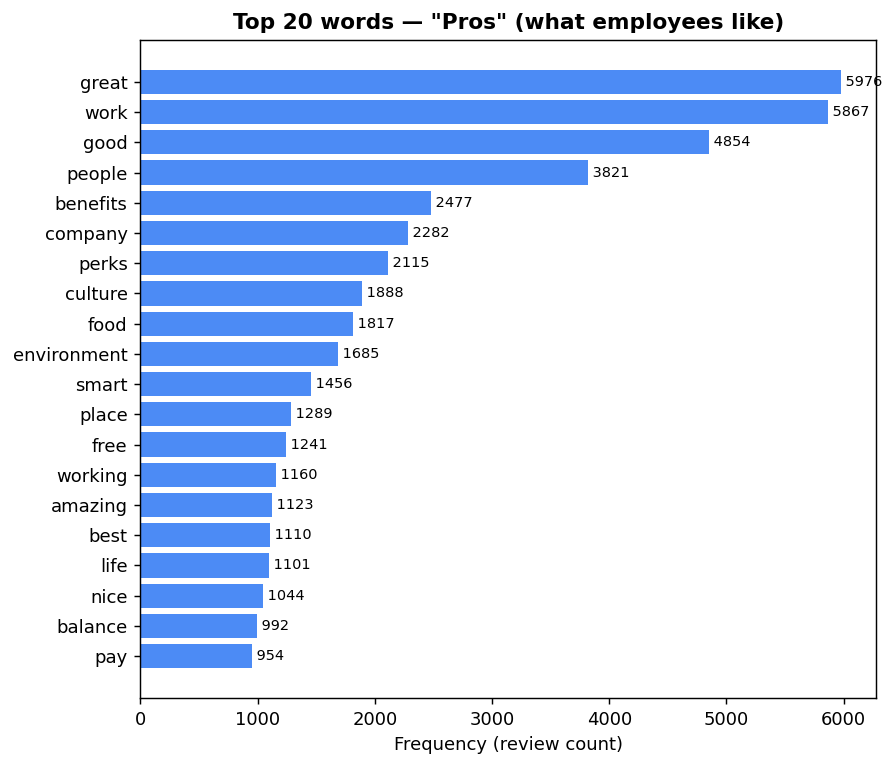

In [15]:
top_words_pros = top_ngrams(df['pros_clean'], (1, 1), top_n=20)
fig = plot_bar(top_words_pros, 'Top 20 words — "Pros" (what employees like)', '#4C8BF5')
fig.savefig('figs/top_words_pros.png', dpi=150, bbox_inches='tight')
plt.show()

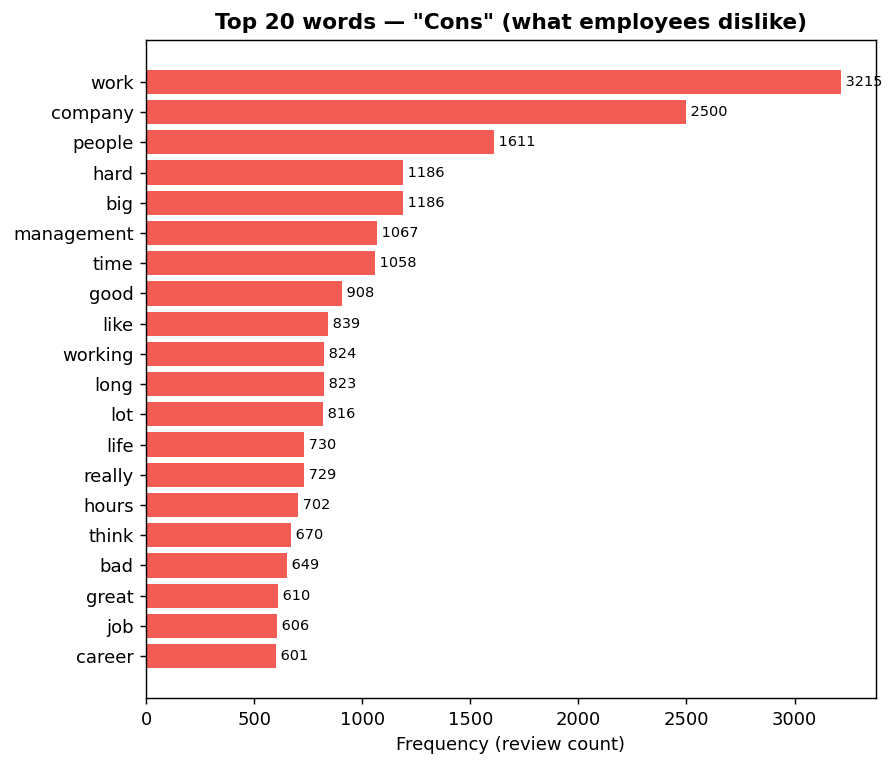

In [16]:
top_words_cons = top_ngrams(df['cons_clean'], (1, 1), top_n=20)
fig = plot_bar(top_words_cons, 'Top 20 words — "Cons" (what employees dislike)', '#F25C54')
fig.savefig('figs/top_words_cons.png', dpi=150, bbox_inches='tight')
plt.show()

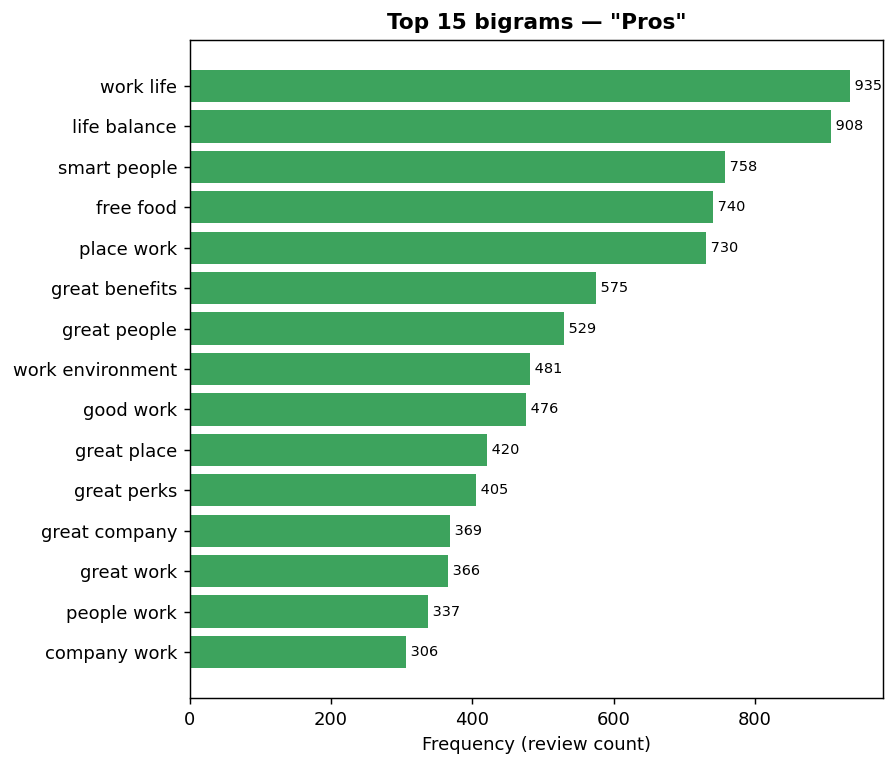

In [17]:
top_bigrams_pros = top_ngrams(df['pros_clean'], (2, 2), top_n=15)
fig = plot_bar(top_bigrams_pros, 'Top 15 bigrams — "Pros"', '#3DA35D')
fig.savefig('figs/top_bigrams_pros.png', dpi=150, bbox_inches='tight')
plt.show()

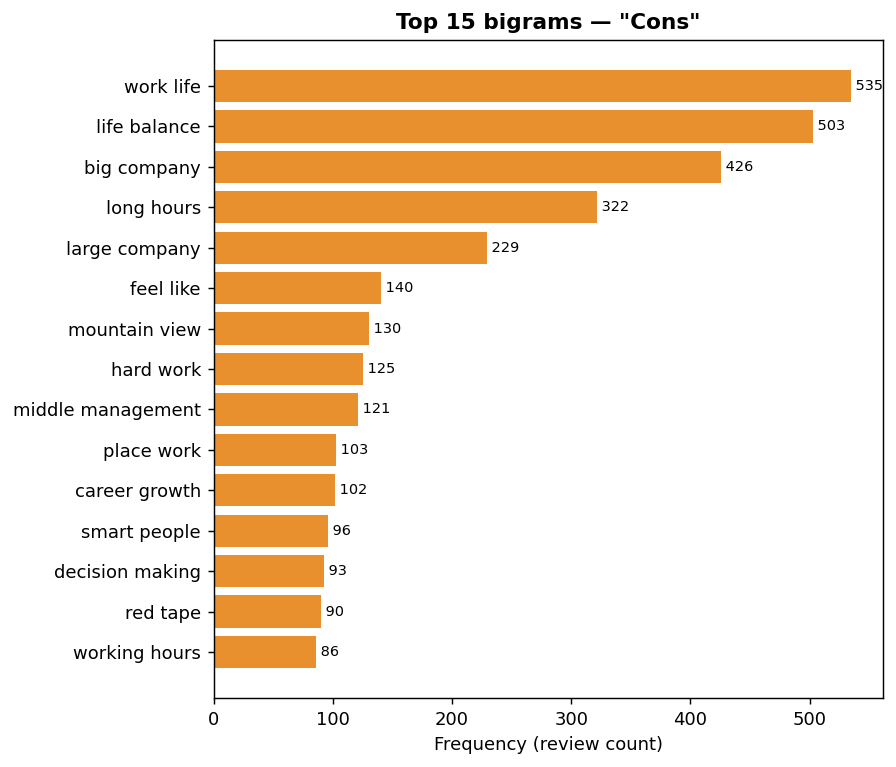

In [18]:
top_bigrams_cons = top_ngrams(df['cons_clean'], (2, 2), top_n=15)
fig = plot_bar(top_bigrams_cons, 'Top 15 bigrams — "Cons"', '#E8902E')
fig.savefig('figs/top_bigrams_cons.png', dpi=150, bbox_inches='tight')
plt.show()

### Observations
- **Pros** center on people, perks, and flexibility: "great", "people", "benefits", "perks",
  "food", "culture", "smart", "balance". The bigrams confirm this: "work life" / "life balance",
  "smart people", "free food", and "great benefits" are the most common two-word phrases.
- **Cons** center on scale and pace: "hard", "big", "management", "time", "long", "hours",
  "career". The bigrams sharpen this further: "big company" / "large company", "long hours",
  "middle management", "career growth" (often paired with "slow"), "red tape", and
  "decision making" — classic complaints about working inside a very large organization.
- Notably, "work life balance" shows up as a strong phrase in **both** pros and cons (935/908
  occurrences in pros vs. 535/503 in cons) — confirming it is a genuinely divisive, high-signal
  topic for Google reviews and a good candidate keyword/topic for the sentiment-modeling stage.

## 5. Next Steps
This cleaned corpus (`google_reviews_clean.csv`) and the keyword frequencies above will feed
into Stage 3: sentiment classification and topic modeling (e.g. LDA / BERTopic) on `pros_clean`
and `cons_clean`, benchmarked against the numeric `overall_rating` and `recommend` labels.

In [ ]:
#Claude was used to assist with code and debugging 